# Notebook 08 + 09：组合回测、交易成本与可交易性约束

本节承接 Notebook 07 的股票评分，把预测信号转成**逐日估值、包含现金的多头账户**，回答：

> 月末评分选出的股票，在下一交易日开盘交易后能否产生超额收益？费用、涨跌停、流动性和降低调仓频率会怎样改变结果？

合并完成 README 的 08 与 09。可复用逻辑在 `src/portfolio/backtest.py`；本 Notebook 固定参数、运行比较、绘图、保存审计表与研究记录，不下载数据，也不更改上游信号。

**研究边界**：使用此前已观察过的历史样本，结果不能称为未触碰的严格样本外检验；该工作仍属于 Notebook 10。

## 1. 固定规则、账户和信息时间轴

- 读取 07 保存的等权、历史 IC、历史 ICIR 和初始训练窗口选定的单因子评分。比较期从四种方法共同就绪的首月开始，候选股票每月都要求当期合格且四种评分齐全；基准使用同一候选股票池全部股票等权。
- 月末**收盘后**生成目标；下一**市场交易日**开盘先卖后买。不能用某只股票的下一条行情代替市场下一交易日。旧仓承担隔夜涨跌，新仓承担执行日开盘后的涨跌。
- 主基准为股票评分前20%等权、每月调仓；前10%是预先固定的敏感性比较。并列评分以股票代码排序，股票数向上取整；目标只读取评分和当时资格，不读取未来收益标签。
- 用 `原价 × 当日复权因子` 的连续单位计算收益与持仓，处理复权变化；**不是**整数股、逐笔撮合或真实现金分红账本。不模拟100股一手、最小佣金、买卖价差及开盘集合竞价排队。
- 初始资金1000万元，不借款、不做空、现金收益设为0。目标金额按交易前NAV计算；先卖后买，买单受费用与可用现金预算限制时等比例缩减。未买成的份额留现金，不分配给其他股票。
- 有效开盘价与复权因子是成交前提。缺失停牌分区时禁止交易；停牌记录只在停牌区间覆盖09:30时禁止开盘成交，空时间视为全天，盘中才开始的停牌不会倒用来拦截开盘。
- 08基准暂不加涨跌停方向限制；09约束版本在开盘价触及涨停时不买、触及跌停时不卖，缺少该侧限价也不交易。这是保守日频假设，不代表实际可成交概率。
- 卖不出的部分保留为旧仓并逐日尝试卖出，遇到下一次调仓则按新目标重新计算；未完成买单当天取消，之后卖出获得的现金不追买旧买单。
- 收盘价缺失只用历史可观察的复权收盘价向前估值，并报告陈旧估值权重与持续天数；不填零、不事后删除持仓。已知退市日到来时，剩余持仓按**零回收压力假设**核销，单独计数和记录金额；这不是实际清算回收率。
- 期末按最后实际收盘估值，不强制清仓、不收取假想清仓费。缓存终点之后无法执行的信号仅保存为待执行信号。

In [1]:
%matplotlib inline
from pathlib import Path
import sys
import json
import time

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.ticker import PercentFormatter
import seaborn as sns
from IPython.display import display, Markdown

PROJECT_ROOT = Path.cwd().resolve()
if not (PROJECT_ROOT / 'src').exists():
    PROJECT_ROOT = PROJECT_ROOT.parent
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))
from src.portfolio import (
    build_portfolio_targets, load_market_data,
    run_portfolio_backtest, summarize_backtest,
)

PROCESSED = PROJECT_ROOT / 'data' / 'processed'
OUTPUT = PROCESSED / 'portfolio_08_09'
FIGURES = PROJECT_ROOT / 'figures'
REPORTS = PROJECT_ROOT / 'reports'
for directory in (OUTPUT, FIGURES, REPORTS):
    directory.mkdir(parents=True, exist_ok=True)
SCORES = ['best_single_score', 'equal_weight_score', 'ic_weight_score', 'icir_weight_score']
INITIAL_CASH = 10_000_000.0
MIN_ADV20 = 20_000_000.0
MAX_ADV_PARTICIPATION = 0.01
sns.set_theme(style='whitegrid', context='notebook')
from matplotlib import font_manager
font_names = {font.name for font in font_manager.fontManager.ttflist}
cjk_fonts = [name for name in ['Arial Unicode MS', 'PingFang HK', 'Microsoft YaHei', 'Noto Sans CJK SC', 'SimHei'] if name in font_names]
if cjk_fonts:
    plt.rcParams['font.sans-serif'] = [*cjk_fonts, 'DejaVu Sans']
plt.rcParams['axes.unicode_minus'] = False
print('解释器：', sys.executable)

解释器： /Users/mac/Desktop/a-share-multifactor/.venv/bin/python


## 2. 只用共同信号样本，独立检查行情覆盖

保留完整股票—月份骨架和最后一月信号。共同评分资格是信号时点条件，**不使用** `is_in_label_sample`、`label_available` 或未来收益筛选股票。

成交额沿用上游清洗后的**元**单位，不再重复乘1000。ADV20按过去20个市场交易日计算，缺行情日成交额按0，停牌日不被跳过。信号筛选可使用信号日收盘ADV；执行容量只使用**前一交易日**已知ADV。日历不完整、月度骨架缺月或关键主键重复会直接报错。

In [2]:
signal_columns = ['date', 'stock_code', 'industry', 'size', 'is_eligible', *SCORES]
source = pd.read_parquet(PROCESSED / 'multifactor_scores.parquet', columns=signal_columns)
source['date'] = pd.to_datetime(source.date)
assert not source.duplicated(['date', 'stock_code']).any()
complete = source[SCORES].notna().all(axis=1) & source.is_eligible.fillna(False)
first_signal = source.loc[complete, 'date'].min()
assert pd.notna(first_signal)
panel = source.loc[source.date.ge(first_signal)].copy()
panel['is_eligible'] = panel.is_eligible.fillna(False) & panel[SCORES].notna().all(axis=1)
signal_dates = pd.DatetimeIndex(sorted(panel.date.unique()))
assert signal_dates.to_period('M').equals(pd.period_range(signal_dates[0], signal_dates[-1], freq='M'))
coverage = panel.groupby('date').agg(total_stocks=('stock_code', 'size'), candidate_stocks=('is_eligible', 'sum'))
market = load_market_data(PROJECT_ROOT, panel)
execution_dates = market.dates.searchsorted(signal_dates, side='right')
signal_audit = coverage.copy()
signal_audit['execution_date'] = [market.dates[i] if i < len(market.dates) else pd.NaT for i in execution_dates]
signal_audit['status'] = np.where(signal_audit.execution_date.notna(), 'executable', 'pending_no_next_market_day')
signal_audit.to_csv(OUTPUT / 'signal_execution_audit.csv')
market_audit = pd.Series({
    'market_start': str(market.dates.min().date()), 'market_end': str(market.dates.max().date()),
    'market_days_with_warmup': len(market.dates), 'stocks': len(market.stocks),
    'missing_suspension_partitions': int((~market.suspension_covered).sum()),
    'signal_months': len(signal_dates), 'candidate_min': int(coverage.candidate_stocks.min()),
    'candidate_max': int(coverage.candidate_stocks.max()),
})
market_audit.to_csv(OUTPUT / 'market_data_audit.csv', header=['value'])
display(market_audit.to_frame('value'))
display(signal_audit.iloc[[0, 1, -2, -1]])
assert (signal_audit.execution_date.dropna() > signal_audit.loc[signal_audit.execution_date.notna()].index).all()

,value
market_start,2021-09-15
market_end,2025-12-31
market_days_with_warmup,1040
stocks,5351
missing_suspension_partitions,0
signal_months,51
candidate_min,3496
candidate_max,4802


,total_stocks,candidate_stocks,execution_date,status
date,,,,
2021-10-29,4525,3626,2021-11-01,executable
2021-11-30,4558,3670,2021-12-01,executable
2025-11-28,5169,4796,2025-12-01,executable
2025-12-31,5183,4791,NaT,pending_no_next_market_day


## 3. 固定情景，不按回测结果重选参数

费用参数为每一侧实际成交额的综合费率：0、10、20、50 bps（1 bp = 0.01%）。它把佣金、税费、滑点和冲击简化为统一假设，**不是**任何历史日期的真实费率或机构成本。

$$Cost_d = (BuyNotional_d + SellNotional_d)\times c/10000$$

单边换手定义为 `0.5 × (买入金额 + 卖出金额) / 当日开盘交易前NAV`，包含首次建仓及延迟卖单；初始满仓建仓对应0.5。月度换手把当月所有执行日相加，样本首尾不完整月份仍保留。成本对应双边成交额，不能误用 `单边换手 × 同一个费率`。

流动性比较分别观察：信号日ADV20至少2000万元的候选池；单只股票当日交易金额不超过前日ADV20的1%。后者也适用于卖单，且不是同日真实成交额占比或集合竞价容量模型。1000万／1亿元初始AUM用于容量敏感性；AUM随实际净值变化。双月／季度分别从共同首个信号月起，每2／3个月调仓，期间不重置持仓。

In [3]:
configs = {
    'ew20_gross': dict(score='equal_weight_score'),
    'single20_gross': dict(score='best_single_score'),
    'ic20_gross': dict(score='ic_weight_score'),
    'icir20_gross': dict(score='icir_weight_score'),
    'ew10_gross': dict(score='equal_weight_score', top_fraction=.1),
    'ew20_cost10': dict(score='equal_weight_score', cost_bps=10),
    'ew20_cost20': dict(score='equal_weight_score', cost_bps=20),
    'ew20_cost50': dict(score='equal_weight_score', cost_bps=50),
    'ew20_limits0': dict(score='equal_weight_score', enforce_limits=True),
    'ew20_limits20': dict(score='equal_weight_score', enforce_limits=True, cost_bps=20),
    'ew20_liquid20': dict(score='equal_weight_score', enforce_limits=True, cost_bps=20, min_adv20=MIN_ADV20),
    'ew20_capacity20': dict(score='equal_weight_score', enforce_limits=True, cost_bps=20, max_adv_participation=MAX_ADV_PARTICIPATION),
    'ew20_capacity100m': dict(score='equal_weight_score', enforce_limits=True, cost_bps=20, max_adv_participation=MAX_ADV_PARTICIPATION, initial_cash=100_000_000.),
    'ew20_every2m': dict(score='equal_weight_score', enforce_limits=True, cost_bps=20, rebalance_every=2),
    'ew20_every3m': dict(score='equal_weight_score', enforce_limits=True, cost_bps=20, rebalance_every=3),
    'benchmark_gross': dict(score=None),
    'benchmark_limits20': dict(score=None, enforce_limits=True, cost_bps=20),
}
config_table = pd.DataFrame(configs).T
config_table.to_csv(OUTPUT / 'scenario_configurations.csv')
display(config_table.fillna('default'))

results, target_tables = {}, {}
started = time.monotonic()
for name, cfg in configs.items():
    target = build_portfolio_targets(
        panel, market, cfg['score'], top_fraction=cfg.get('top_fraction', .2),
        rebalance_every=cfg.get('rebalance_every', 1), min_adv20=cfg.get('min_adv20', 0),
    )
    result = run_portfolio_backtest(
        market, target, initial_cash=cfg.get('initial_cash', INITIAL_CASH),
        cost_bps=cfg.get('cost_bps', 0), enforce_limits=cfg.get('enforce_limits', False),
        max_adv_participation=cfg.get('max_adv_participation'),
    )
    results[name], target_tables[name] = result, target
    print(f'{name:24s}  {len(result.daily):4d} days  {len(result.trades):7,d} requests')
print(f'全部情景耗时：{time.monotonic() - started:.1f}秒')

,score,top_fraction,cost_bps,enforce_limits,min_adv20,max_adv_participation,initial_cash,rebalance_every
ew20_gross,equal_weight_score,default,default,default,default,default,default,default
single20_gross,best_single_score,default,default,default,default,default,default,default
ic20_gross,ic_weight_score,default,default,default,default,default,default,default
icir20_gross,icir_weight_score,default,default,default,default,default,default,default
ew10_gross,equal_weight_score,0.1,default,default,default,default,default,default
ew20_cost10,equal_weight_score,default,10,default,default,default,default,default
ew20_cost20,equal_weight_score,default,20,default,default,default,default,default
ew20_cost50,equal_weight_score,default,50,default,default,default,default,default
ew20_limits0,equal_weight_score,default,default,True,default,default,default,default
ew20_limits20,equal_weight_score,default,20,True,default,default,default,default


ew20_gross                1014 days   53,788 requests


single20_gross            1014 days   56,030 requests


ic20_gross                1014 days   54,411 requests


icir20_gross              1014 days   53,973 requests


...

ew20_capacity100m         1014 days   53,978 requests


ew20_every2m              1014 days   28,555 requests


ew20_every3m              1014 days   20,389 requests


benchmark_gross           1014 days  223,712 requests


benchmark_limits20        1014 days  225,151 requests
全部情景耗时：14.9秒


## 4. 账户绩效、成本和约束比较

全部情景采用共同起点、共同缓存终点，保留末尾仍在持有的天数。日收益为 `NAV_d/NAV_(d-1)-1`；首日以初始资金为分母，首日费用和损益不会消失。年化使用252个交易日；CAGR用复利，Sharpe用日算术平均收益／日收益样本标准差×√252，Rf=0；最大回撤包含初始净值。

同时展示对**毛收益股票池基准**和**相同20bps＋限价规则基准**的相对净值年化增长。前者是更高的比较门槛；不能把净策略与毛基准的差异解释成纯选股能力。相对净值为 `策略NAV / 基准NAV`，不是简单累计日收益差。

In [4]:
returns = pd.DataFrame({name: result.daily['return'] for name, result in results.items()})
assert returns.notna().all().all(), '比较情景必须使用完全相同的交易日'
nav = returns.add(1).cumprod()
summary = pd.DataFrame({name: summarize_backtest(result, configs[name].get('initial_cash', INITIAL_CASH))
                        for name, result in results.items()}).T
for bench in ['benchmark_gross', 'benchmark_limits20']:
    relative = nav.div(nav[bench], axis=0)
    summary[f'Relative CAGR vs {bench}'] = relative.iloc[-1] ** (252 / len(relative)) - 1
summary.to_csv(OUTPUT / 'performance_summary.csv')
returns.to_parquet(OUTPUT / 'daily_returns.parquet')
nav.to_parquet(OUTPUT / 'normalized_nav.parquet')
display_columns = ['Annualized Return', 'Annualized Volatility', 'Sharpe', 'Max Drawdown',
                   'Mean Monthly Turnover', 'Mean Cash Weight', 'Relative CAGR vs benchmark_gross']
display(summary[display_columns].style.format({c:'{:.2%}' for c in display_columns if c != 'Sharpe'} | {'Sharpe':'{:.2f}'}))

fee_comparison = summary.loc[['ew20_gross', 'ew20_cost10', 'ew20_cost20', 'ew20_cost50'],
                             ['Annualized Return', 'Sharpe', 'Max Drawdown', 'Total Cost / Initial AUM']]
constraint_comparison = summary.loc[['ew20_cost20', 'ew20_limits20', 'ew20_liquid20',
                                     'ew20_capacity20', 'ew20_capacity100m', 'ew20_every2m', 'ew20_every3m'], display_columns]
display(fee_comparison.style.format('{:.4f}'))
display(constraint_comparison.style.format('{:.4f}'))

,Annualized Return,Annualized Volatility,Sharpe,Max Drawdown,Mean Monthly Turnover,Mean Cash Weight,Relative CAGR vs benchmark_gross
ew20_gross,15.68%,22.29%,0.77,-27.86%,26.49%,0.04%,3.04%
single20_gross,18.24%,22.03%,0.87,-29.76%,30.85%,0.05%,5.32%
ic20_gross,18.16%,21.91%,0.87,-28.66%,27.43%,0.04%,5.25%
icir20_gross,18.31%,21.92%,0.88,-28.21%,26.51%,0.04%,5.38%
ew10_gross,14.78%,21.74%,0.74,-26.55%,30.32%,0.05%,2.24%
ew20_cost10,14.92%,22.27%,0.74,-28.27%,26.47%,0.04%,2.37%
ew20_cost20,14.17%,22.26%,0.71,-28.68%,26.44%,0.04%,1.70%
ew20_cost50,11.95%,22.22%,0.62,-29.90%,26.35%,0.04%,-0.28%
ew20_limits0,15.67%,22.22%,0.77,-27.89%,26.40%,0.24%,3.03%
ew20_limits20,14.16%,22.18%,0.71,-28.72%,26.35%,0.23%,1.69%


,Annualized Return,Sharpe,Max Drawdown,Total Cost / Initial AUM
ew20_gross,0.1568,0.7659,-0.2786,0.0000
ew20_cost10,0.1492,0.7368,-0.2827,0.0321
ew20_cost20,0.1417,0.7076,-0.2868,0.0632
ew20_cost50,0.1195,0.6202,-0.2990,0.1513


,Annualized Return,Annualized Volatility,Sharpe,Max Drawdown,Mean Monthly Turnover,Mean Cash Weight,Relative CAGR vs benchmark_gross
ew20_cost20,0.1417,0.2226,0.7076,-0.2868,0.2644,0.0004,0.0170
ew20_limits20,0.1416,0.2218,0.7089,-0.2872,0.2635,0.0023,0.0169
ew20_liquid20,0.1260,0.2222,0.6461,-0.2931,0.2890,0.0023,0.0030
ew20_capacity20,0.1416,0.2218,0.7089,-0.2872,0.2635,0.0023,0.0169
ew20_capacity100m,0.1399,0.2215,0.7027,-0.2872,0.2625,0.0046,0.0153
ew20_every2m,0.1368,0.2219,0.6899,-0.2716,0.1758,0.0012,0.0126
ew20_every3m,0.1346,0.2242,0.6764,-0.2819,0.1473,0.0018,0.0107


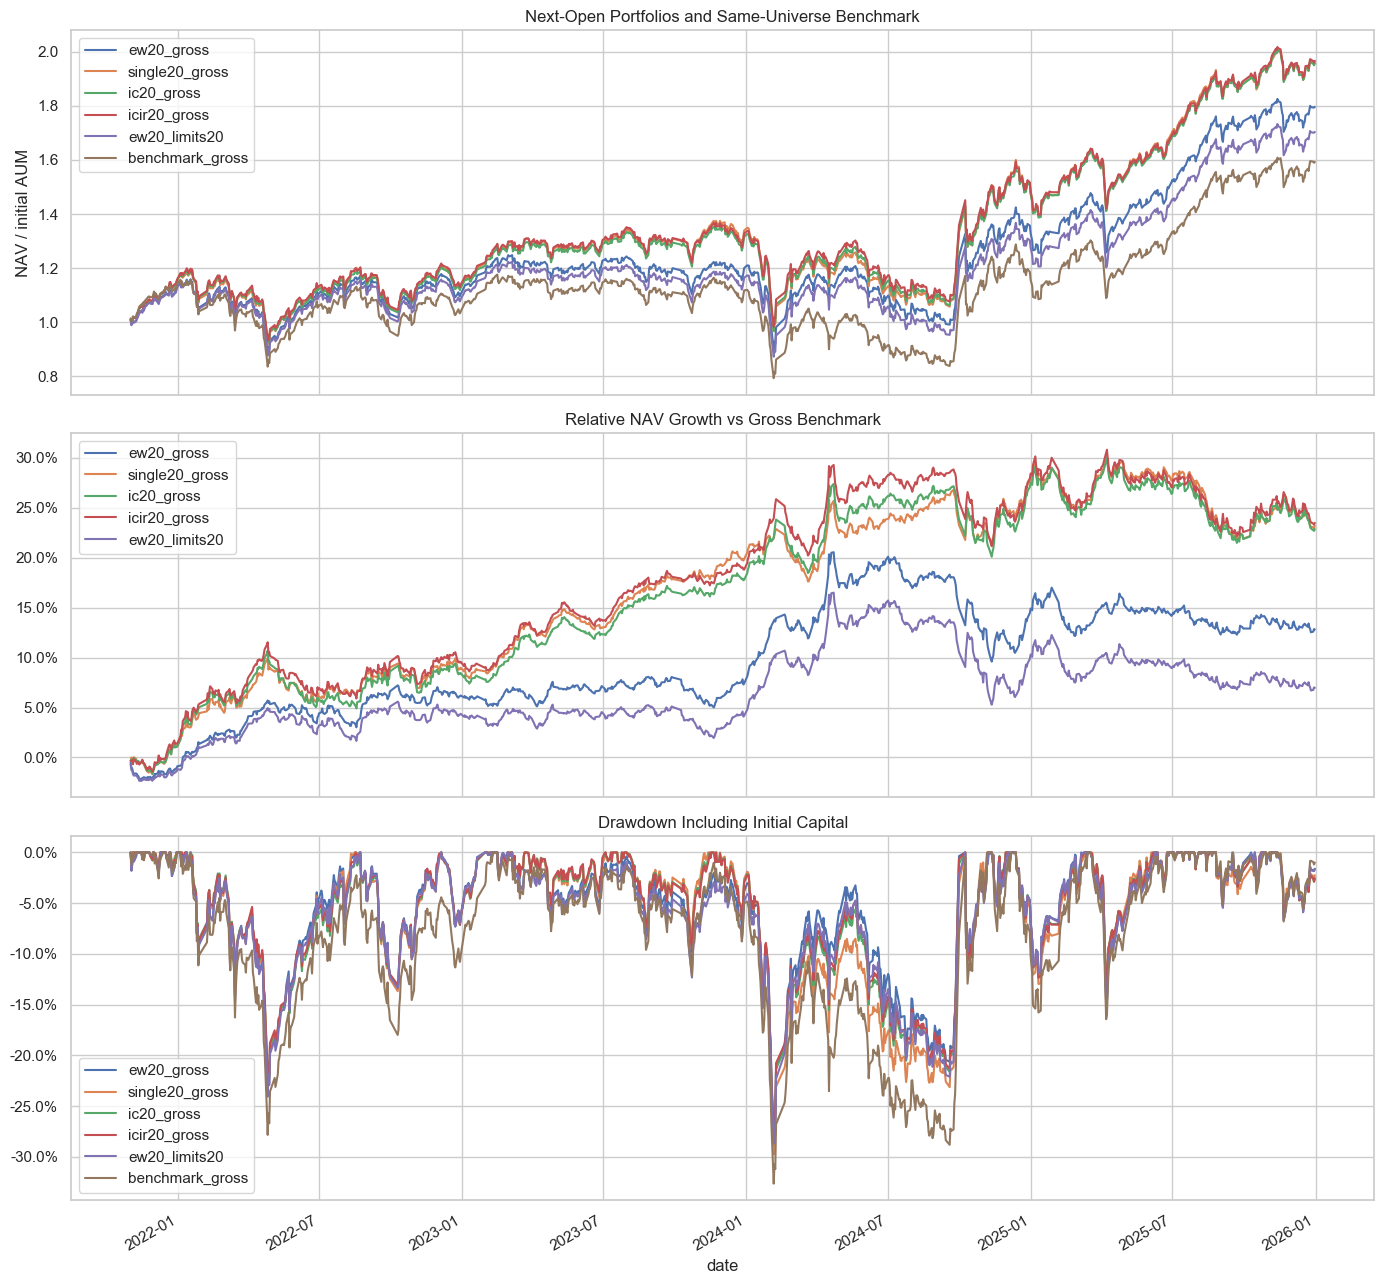

In [5]:
main_names = ['ew20_gross', 'single20_gross', 'ic20_gross', 'icir20_gross', 'ew20_limits20', 'benchmark_gross']
fig, axes = plt.subplots(3, 1, figsize=(14, 13), sharex=True)
nav[main_names].plot(ax=axes[0])
axes[0].set_title('Next-Open Portfolios and Same-Universe Benchmark')
axes[0].set_ylabel('NAV / initial AUM')
relative = nav[main_names[:-1]].div(nav.benchmark_gross, axis=0).sub(1)
relative.plot(ax=axes[1])
axes[1].set_title('Relative NAV Growth vs Gross Benchmark')
axes[1].yaxis.set_major_formatter(PercentFormatter(1))
# cummax至少为1，首日下跌也计入回撤。
drawdown = nav[main_names].div(nav[main_names].cummax().clip(lower=1)).sub(1)
drawdown.plot(ax=axes[2])
axes[2].set_title('Drawdown Including Initial Capital')
axes[2].yaxis.set_major_formatter(PercentFormatter(1))
fig.tight_layout()
fig.savefig(FIGURES / 'portfolio_08_09_nav_excess_drawdown.png', dpi=150, bbox_inches='tight')
plt.show()

## 5. 月收益、滚动12个月Sharpe与换手

月收益复合当月实际交易日收益；首尾不完整月份标记并保留。滚动Sharpe使用12个日历月份收益、样本标准差、√12年化，首个满12个月窗口后展示。它与核心表的日频Sharpe频率不同。

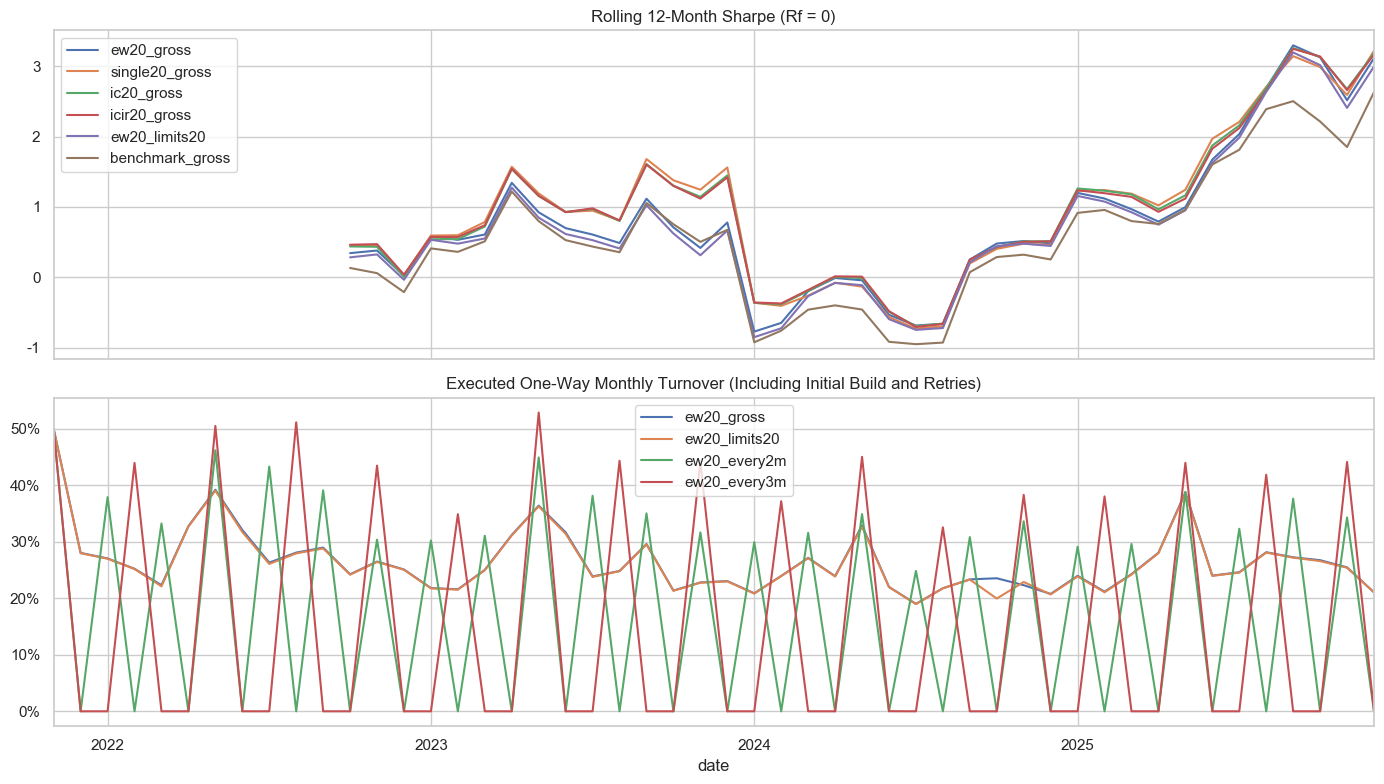

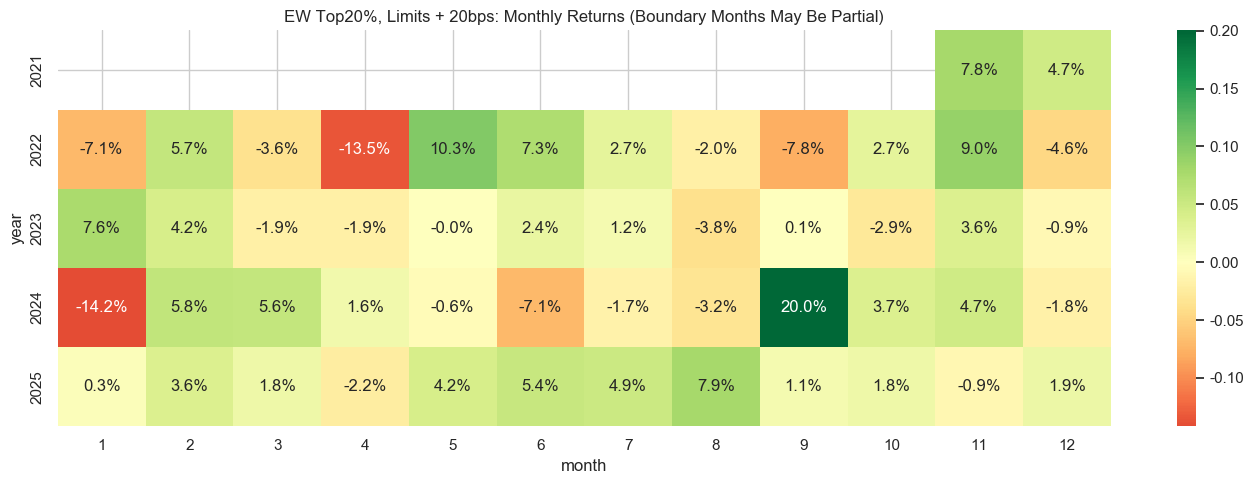

In [6]:
monthly = returns.groupby(returns.index.to_period('M')).agg(lambda r: (1 + r).prod() - 1)
monthly.to_csv(OUTPUT / 'monthly_returns.csv')
turnover = pd.DataFrame({name: result.daily.one_way_turnover.groupby(result.daily.index.to_period('M')).sum()
                         for name, result in results.items()})
turnover.to_csv(OUTPUT / 'monthly_turnover.csv')
rolling_sharpe = monthly.rolling(12, min_periods=12).mean().div(monthly.rolling(12, min_periods=12).std(ddof=1)).mul(np.sqrt(12))
rolling_sharpe = rolling_sharpe.replace([np.inf, -np.inf], np.nan)
fig, axes = plt.subplots(2, 1, figsize=(14, 8), sharex=True)
rolling_sharpe[main_names].set_axis(monthly.index.to_timestamp()).plot(ax=axes[0])
axes[0].set_title('Rolling 12-Month Sharpe (Rf = 0)')
turnover[['ew20_gross', 'ew20_limits20', 'ew20_every2m', 'ew20_every3m']].set_axis(turnover.index.to_timestamp()).plot(ax=axes[1])
axes[1].set_title('Executed One-Way Monthly Turnover (Including Initial Build and Retries)')
axes[1].yaxis.set_major_formatter(PercentFormatter(1))
fig.tight_layout()
fig.savefig(FIGURES / 'portfolio_08_09_sharpe_turnover.png', dpi=150, bbox_inches='tight')
plt.show()

heat = monthly['ew20_limits20'].rename('return').reset_index()
heat['year'] = heat.date.dt.year
heat['month'] = heat.date.dt.month
fig, ax = plt.subplots(figsize=(14, 5))
sns.heatmap(heat.pivot(index='year', columns='month', values='return').reindex(columns=range(1,13)),
            annot=True, fmt='.1%', cmap='RdYlGn', center=0, ax=ax)
ax.set_title('EW Top20%, Limits + 20bps: Monthly Returns (Boundary Months May Be Partial)')
fig.tight_layout()
fig.savefig(FIGURES / 'portfolio_08_09_monthly_heatmap.png', dpi=150, bbox_inches='tight')
plt.show()

## 6. 成本、容量与调仓频率的影响

这些都是预先固定的情景敏感性，不把效果最好的参数重新设为主策略。降低频率可能减少成交，也可能让评分变旧；高成交额筛选和容量上限可能改变股票池／现金比例，不能把它们的差异归因于费用一项。

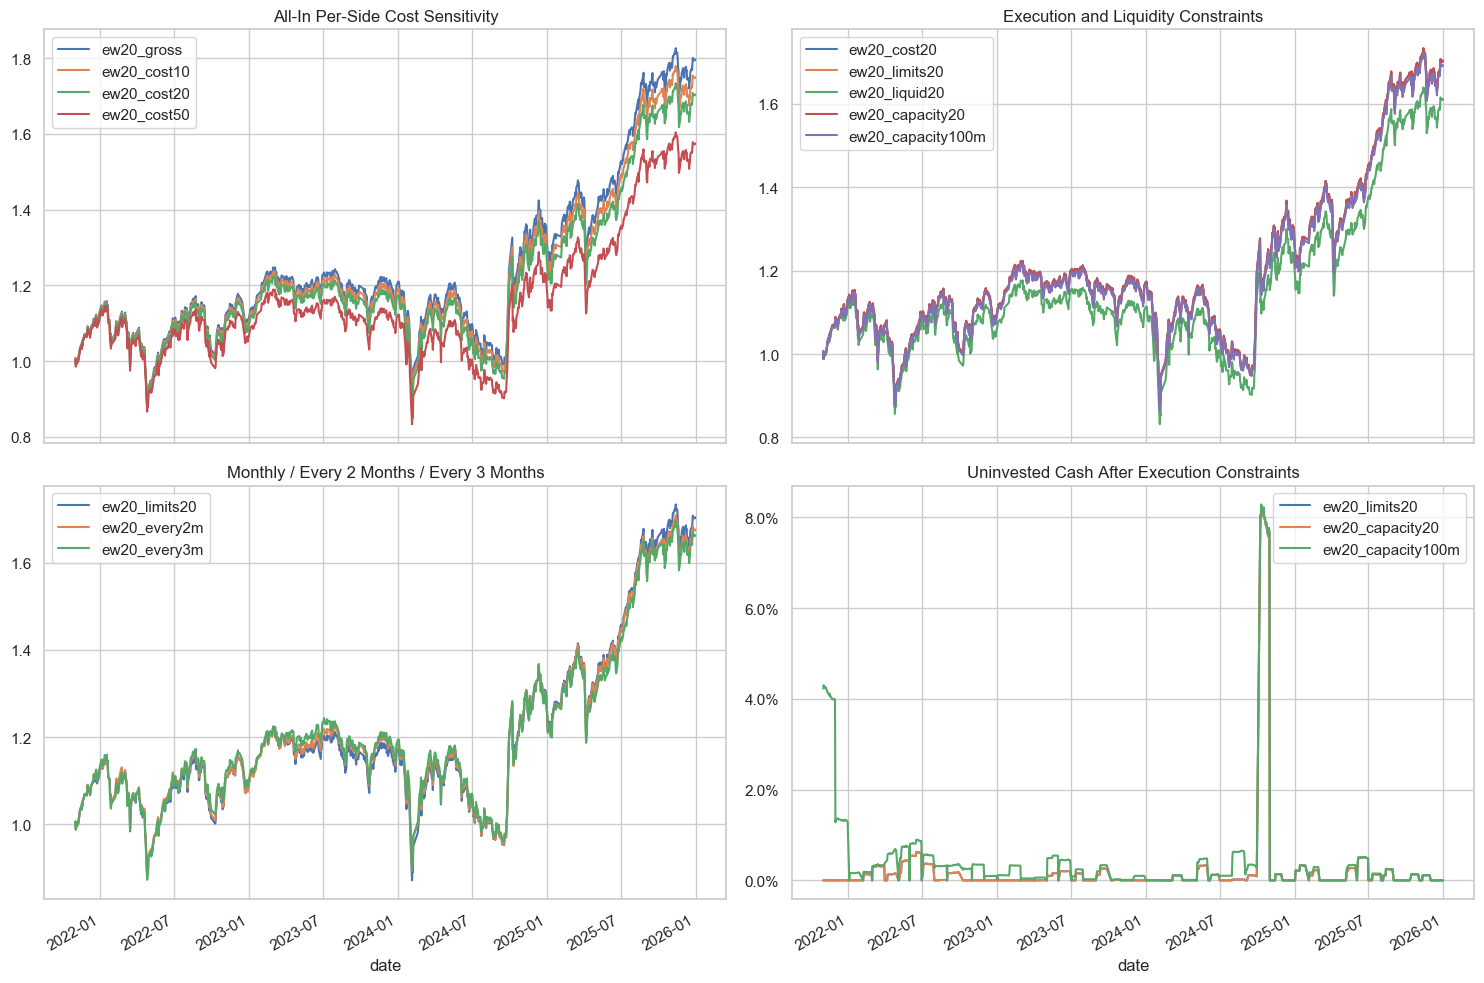

In [7]:
fig, axes = plt.subplots(2, 2, figsize=(15, 10), sharex=True)
nav[['ew20_gross', 'ew20_cost10', 'ew20_cost20', 'ew20_cost50']].plot(ax=axes[0,0])
axes[0,0].set_title('All-In Per-Side Cost Sensitivity')
nav[['ew20_cost20', 'ew20_limits20', 'ew20_liquid20', 'ew20_capacity20', 'ew20_capacity100m']].plot(ax=axes[0,1])
axes[0,1].set_title('Execution and Liquidity Constraints')
nav[['ew20_limits20', 'ew20_every2m', 'ew20_every3m']].plot(ax=axes[1,0])
axes[1,0].set_title('Monthly / Every 2 Months / Every 3 Months')
cash_weights = pd.DataFrame({name: result.daily.cash_weight for name, result in results.items()})
cash_weights[['ew20_limits20', 'ew20_capacity20', 'ew20_capacity100m']].plot(ax=axes[1,1])
axes[1,1].set_title('Uninvested Cash After Execution Constraints')
axes[1,1].yaxis.set_major_formatter(PercentFormatter(1))
fig.tight_layout()
fig.savefig(FIGURES / 'portfolio_08_09_cost_constraints.png', dpi=150, bbox_inches='tight')
plt.show()

## 7. 行业、市值暴露：检查实际持仓

中性化因子不保证选股后的组合中性。以下使用每月执行日收盘**实际持仓权重**，连接该执行日前最新月末的行业与 `size = log(总市值)`，不使用未来行业分类。无法连接的旧仓行业列为Unknown，市值列保留缺失并统计覆盖率。市值来源是自然对数市值，不是标准化因子。

行业图包含现金，总权重应为100%；市值图对已知市值的股票持仓重新归一化，并同时提供已知持仓权重覆盖，不能把现金或未知市值默认为0市值。

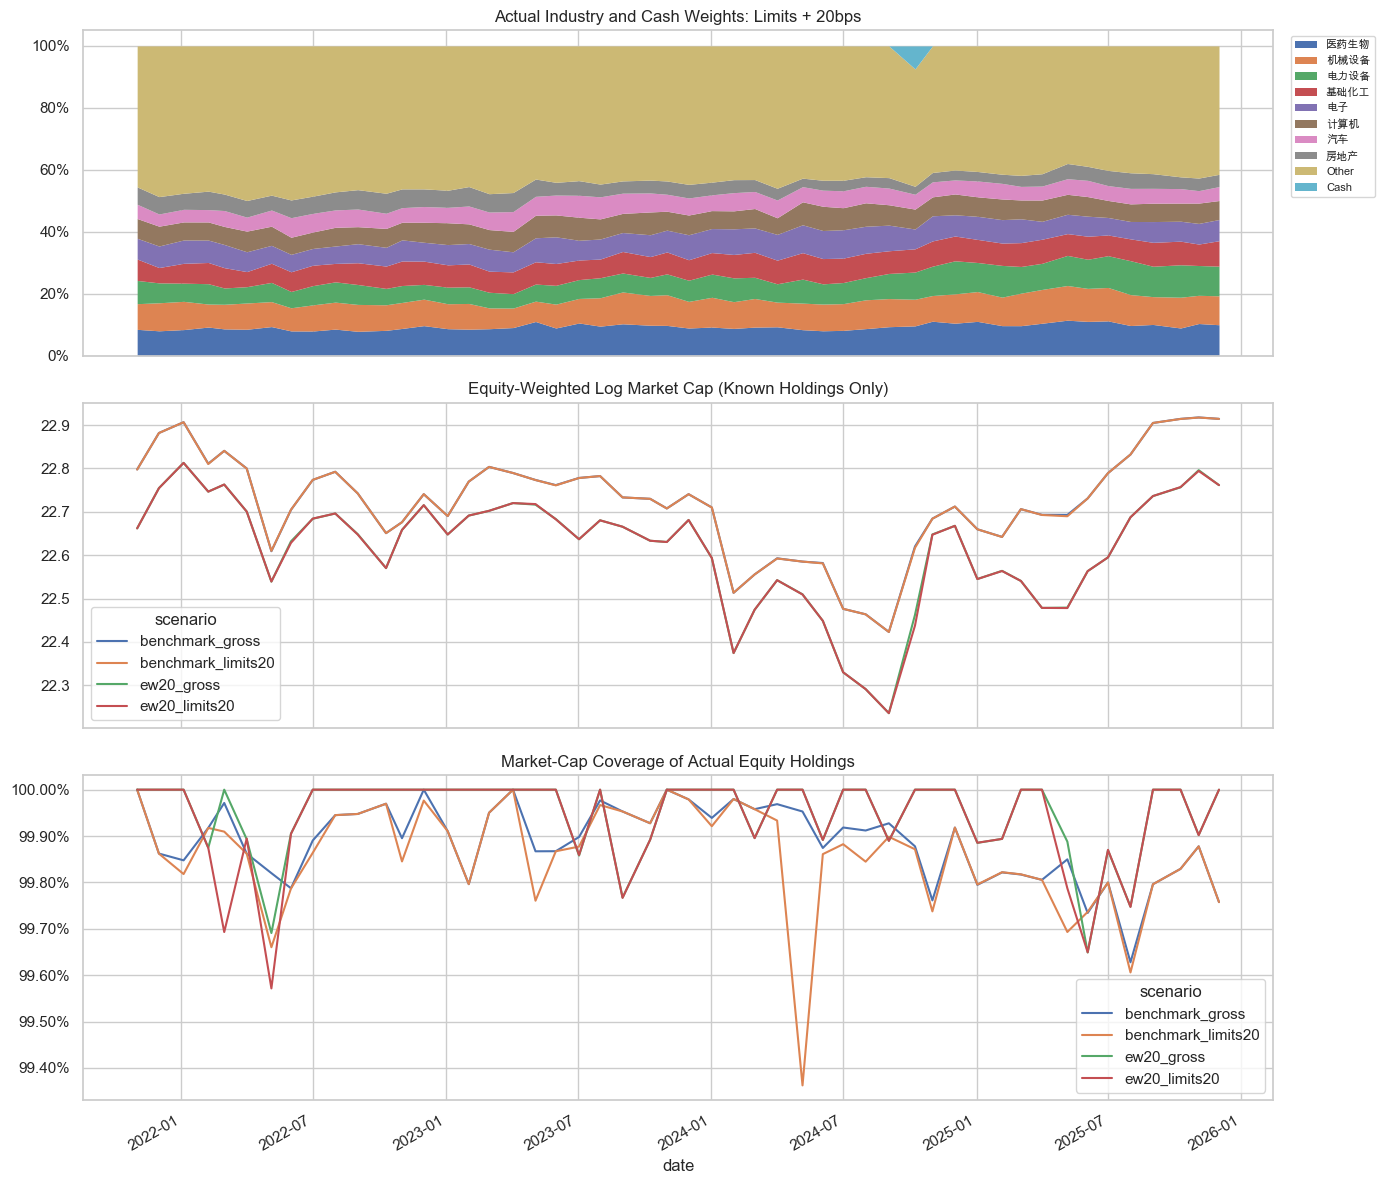

In [8]:
exposure_frames = []
metadata = panel[['date', 'stock_code', 'industry', 'size']].rename(columns={'date':'signal_date'})
for name in ['ew20_gross', 'ew20_limits20', 'benchmark_gross', 'benchmark_limits20']:
    h = results[name].holdings.merge(metadata, on=['signal_date', 'stock_code'], how='left', validate='many_to_one')
    h['industry'] = h.industry.fillna('Unknown')
    h['scenario'] = name
    exposure_frames.append(h)
exposures = pd.concat(exposure_frames, ignore_index=True)
industry = exposures.groupby(['scenario', 'date', 'industry']).weight.sum().unstack('industry', fill_value=0)
industry['Cash'] = 1 - industry.sum(axis=1)
industry.to_csv(OUTPUT / 'industry_exposure.csv')
exposures['known_size_weight'] = exposures.weight.where(exposures['size'].notna(), 0)
exposures['weighted_size'] = exposures.weight * exposures['size']
size_exposure = exposures.groupby(['scenario', 'date']).agg(known_weight=('known_size_weight','sum'),
                                                         weighted_size=('weighted_size','sum'), equity_weight=('weight','sum'))
size_exposure['mean_log_market_cap'] = size_exposure.weighted_size / size_exposure.known_weight.replace(0,np.nan)
size_exposure['size_coverage_of_equity'] = size_exposure.known_weight / size_exposure.equity_weight.replace(0,np.nan)
size_exposure.to_csv(OUTPUT / 'size_exposure.csv')
assert np.allclose(industry.sum(axis=1), 1)
primary_industry = industry.loc['ew20_limits20']
top_industries = primary_industry.drop(columns=['Cash']).mean().nlargest(8).index
plot_industry = primary_industry.loc[:, top_industries].copy()
plot_industry['Other'] = primary_industry.drop(columns=[*top_industries, 'Cash']).sum(axis=1)
plot_industry['Cash'] = primary_industry.Cash
fig, axes = plt.subplots(3, 1, figsize=(14, 12), sharex=True)
plot_industry.clip(lower=0).plot.area(ax=axes[0], linewidth=0)
axes[0].set_title('Actual Industry and Cash Weights: Limits + 20bps')
axes[0].yaxis.set_major_formatter(PercentFormatter(1))
axes[0].legend(loc='upper left', bbox_to_anchor=(1.01,1), fontsize=8)
size_exposure.mean_log_market_cap.unstack('scenario').plot(ax=axes[1])
axes[1].set_title('Equity-Weighted Log Market Cap (Known Holdings Only)')
size_exposure.size_coverage_of_equity.unstack('scenario').plot(ax=axes[2])
axes[2].set_title('Market-Cap Coverage of Actual Equity Holdings')
axes[2].yaxis.set_major_formatter(PercentFormatter(1))
fig.tight_layout()
fig.savefig(FIGURES / 'portfolio_08_09_exposures.png', dpi=150, bbox_inches='tight')
plt.show()

## 8. 受阻交易、陈旧估值与资金审计

订单表保留受阻和部分成交请求；`reason`为最终限制原因，`cash_scaled`表示费用／资金预算缩减。跨天重试卖单会形成多行请求，因此“请求金额总和”不是互不重复的策略原始意向金额，不能直接解释成成交率。实际成交额与实际费用可直接汇总。

核销只减少NAV而不生成虚假卖出成交；陈旧价格可能低估停牌期间的真实风险，表中持续天数与权重用于揭示该限制。

本地 `stock_basic.delist_date` 也可能包含吸收合并、换股终止上市等公司事件。缺少现金补偿或换股对价数据时，本回测统一零回收，可能低估这些持仓的经济价值；请结合各情景 `*_writeoffs.parquet` 的逐股明细理解结果。

In [9]:
order_audits = []
for name, result in results.items():
    a = result.trades.groupby(['side','reason']).agg(request_rows=('stock_code','size'),
                requested_notional=('requested_notional','sum'), filled_notional=('filled_notional','sum'), cost=('cost','sum')).reset_index()
    a.insert(0, 'scenario', name)
    order_audits.append(a)
order_audit = pd.concat(order_audits, ignore_index=True)
order_audit.to_csv(OUTPUT / 'order_execution_audit.csv', index=False)
display(order_audit.loc[order_audit.scenario.isin(['ew20_limits20','ew20_capacity20','ew20_capacity100m'])])
display(summary[['Max Stale Weight', 'Max Stale Days', 'Writeoff Count', 'Writeoff / Initial AUM', 'Total Cost / Initial AUM']].style.format('{:.5f}'))

for name, result in results.items():
    initial = configs[name].get('initial_cash', INITIAL_CASH)
    assert np.isfinite(result.daily.nav).all() and result.daily.nav.gt(0).all()
    assert result.daily.cash_weight.between(-1e-10, 1+1e-10).all()
    assert np.allclose((1 + result.daily['return']).cumprod(), result.daily.nav / initial)
    expected_cost = result.trades.filled_notional.sum() * configs[name].get('cost_bps',0) / 10000
    assert np.isclose(result.daily.cost.sum(), expected_cost)
    assert result.trades.date.min() > first_signal
    assert result.trades.filled_notional.le(result.trades.requested_notional + 1e-6).all()
    if configs[name].get('enforce_limits', False):
        blocked = result.trades.reason.isin(['limit_up','limit_down','missing_limit','missing_open','suspended_or_uncovered'])
        assert result.trades.loc[blocked, 'filled_notional'].eq(0).all()
    result.daily.to_parquet(OUTPUT / f'{name}_daily.parquet')
    result.trades.to_parquet(OUTPUT / f'{name}_orders.parquet', index=False)
    result.holdings.to_parquet(OUTPUT / f'{name}_holdings.parquet', index=False)
    result.writeoffs.to_parquet(OUTPUT / f'{name}_writeoffs.parquet', index=False)
    assert np.isclose(result.writeoffs.writeoff_value.sum(), result.daily.writeoff_value.sum())
    target_long = target_tables[name].rename_axis(columns='stock_code').stack().rename('weight')
    target_long = target_long.loc[target_long.gt(0)].reset_index()
    target_long.to_parquet(OUTPUT / f'{name}_targets.parquet', index=False)
print('通过：净值复利一致、现金非负、费用与实际成交额一致、受阻订单零成交。')

,scenario,side,reason,request_rows,requested_notional,filled_notional,cost
46,ew20_limits20,buy,cash_scaled,28474,1.589259e+08,1.576733e+08,3.153466e+05
47,ew20_limits20,buy,filled,1042,4.434713e+06,4.434713e+06,8.869426e+03
48,ew20_limits20,buy,limit_up,225,1.003632e+06,0.000000e+00,0.000000e+00
49,ew20_limits20,buy,missing_open,11,2.768347e+04,0.000000e+00,0.000000e+00
50,ew20_limits20,sell,filled,23810,1.527377e+08,1.527377e+08,3.054754e+05
51,ew20_limits20,sell,limit_down,43,5.865135e+05,0.000000e+00,0.000000e+00
52,ew20_limits20,sell,missing_open,204,2.207702e+06,0.000000e+00,0.000000e+00
60,ew20_capacity20,buy,cash_scaled,28474,1.589259e+08,1.576733e+08,3.153466e+05
61,ew20_capacity20,buy,filled,1042,4.434713e+06,4.434713e+06,8.869426e+03
62,ew20_capacity20,buy,limit_up,225,1.003632e+06,0.000000e+00,0.000000e+00


,Max Stale Weight,Max Stale Days,Writeoff Count,Writeoff / Initial AUM,Total Cost / Initial AUM
ew20_gross,0.00789,33.00000,1.00000,0.00129,0.00000
single20_gross,0.00701,45.00000,1.00000,0.00206,0.00000
ic20_gross,0.00533,42.00000,0.00000,0.00000,0.00000
icir20_gross,0.00640,42.00000,0.00000,0.00000,0.00000
ew10_gross,0.00687,10.00000,0.00000,0.00000,0.00000
ew20_cost10,0.00789,33.00000,1.00000,0.00127,0.03210
ew20_cost20,0.00790,33.00000,1.00000,0.00125,0.06325
ew20_cost50,0.00792,33.00000,1.00000,0.00120,0.15128
ew20_limits0,0.00789,33.00000,1.00000,0.00129,0.00000
ew20_limits20,0.00790,33.00000,1.00000,0.00125,0.06297


通过：净值复利一致、现金非负、费用与实际成交额一致、受阻订单零成交。


## 9. 逐年表现、自动结论与复现

逐年结果按收益实际发生日期划分，包含执行日隔夜收益和费用；边界年份可能不满一年。结论只陈述固定情景的实测差异，不宣称统计显著或已经验证可投资alpha。

输出：`data/processed/portfolio_08_09/` 中的目标持仓、实际持仓、逐笔请求、日收益、净值、绩效、月收益、行业／市值暴露及执行审计；`figures/portfolio_08_09_*.png`；`reports/08_09_portfolio_backtest_and_constraints.md`。

从项目根目录或notebooks目录选择项目 `.venv` 内核后按顺序运行。依赖 07 的评分、02 的清洗后日行情及01的交易日历／停牌分区／股票基础信息。手算测试命令：`python -m pytest tests/test_portfolio_backtest.py -q`。

In [10]:
yearly_rows = []
for name in main_names:
    for year, r in returns[name].groupby(returns.index.year):
        yearly_rows.append({'scenario':name, 'year':year, 'days':len(r),
                            'realized_return':(1+r).prod()-1,
                            'annualized_volatility':r.std(ddof=1)*np.sqrt(252),
                            'sharpe':r.mean()/r.std(ddof=1)*np.sqrt(252) if r.std(ddof=1)>0 else np.nan})
yearly = pd.DataFrame(yearly_rows)
yearly.to_csv(OUTPUT / 'yearly_results.csv', index=False)
display(yearly.pivot(index='year', columns='scenario', values='realized_return').style.format('{:.2%}'))

conclusions = []
for name in ['ew20_gross','ew20_limits20','benchmark_gross','benchmark_limits20']:
    row = summary.loc[name]
    conclusions.append(f"{name}：年化收益 {row['Annualized Return']:.2%}，Sharpe {row['Sharpe']:.2f}，最大回撤 {row['Max Drawdown']:.2%}，平均月度单边换手 {row['Mean Monthly Turnover']:.2%}。")
conclusions.append(f"固定20bps费用相对零费用：年化收益变化 {summary.loc['ew20_cost20','Annualized Return']-summary.loc['ew20_gross','Annualized Return']:+.2%}。")
conclusions.append(f"20bps基础上加入涨跌停限制：年化收益变化 {summary.loc['ew20_limits20','Annualized Return']-summary.loc['ew20_cost20','Annualized Return']:+.2%}；这是执行路径差异，不是独立费用。")
for name in ['ew20_liquid20','ew20_capacity20','ew20_capacity100m','ew20_every2m','ew20_every3m']:
    row = summary.loc[name]
    conclusions.append(f"{name}：年化收益 {row['Annualized Return']:.2%}，平均月度单边换手 {row['Mean Monthly Turnover']:.2%}，平均现金 {row['Mean Cash Weight']:.2%}。")
report_lines = [
    '# Notebook 08 + 09：组合回测与交易约束运行记录', '',
    '## 固定规则', '',
    f'- 信号月：{signal_dates.min():%Y-%m-%d}至{signal_dates.max():%Y-%m-%d}；实际账户：{returns.index.min():%Y-%m-%d}至{returns.index.max():%Y-%m-%d}，共{len(returns)}个交易日。',
    '- 四种评分共同完整样本；基准为同一候选池等权；主策略四因子等权评分Top20%，另固定比较Top10%。',
    '- 月末收盘后信号，下一市场交易日开盘先卖后买；连续复权单位，不借款、不做空、现金收益0。',
    '- 初始1000万元；另以1亿元测试容量。成本0/10/20/50bps按实际双边成交额收取，包含首日。',
    '- 约束版本开盘涨停不买、跌停不卖；缺少对应限价或停牌分区不交易。只拦截开盘时段停牌，不倒用盘中停牌。',
    '- 卖单受阻逐日重试，新调仓覆盖旧意向；买单不重试，未成交部分留现金，不事后补入其他股票。',
    '- 信号ADV20门槛2000万元；容量上限为前日已知ADV20的1%；分别比较每1/2/3个月调仓。',
    '- 缺收盘价向前估值，显示陈旧权重与天数；退市剩余仓位按零回收压力假设核销，非实际清算回收率。',
    '- 期末按市值计价，不强制平仓。最后无下一市场交易日的信号仅保留，不用未来标签筛选目标。',
    '- CAGR与波动率按日频252年化；Sharpe为日均值/样本标准差×√252，Rf=0；回撤包含初始资金。',
    '- 月换手为当月实际执行日0.5×双边成交额/开盘交易前NAV之和，包含首次建仓和延迟交易。',
    '', '## 实测结果', '', *['- '+s for s in conclusions], '',
    '```text', summary.round(6).to_string(), '```', '',
    '## 解释边界', '',
    '- 前序研究已观察过这些数据，没有独立隔离最终测试集；不能称为未触碰的样本外验证。',
    '- 毛股票池基准与20bps+限价基准同时展示；相对CAGR来自相对净值增长，不是年化收益的简单差。',
    '- 统一bps是敏感性参数，不是真实历史税费、佣金或冲击估计。',
    '- 连续复权单位未模拟整数股、最小佣金、集合竞价排队、实际现金分红与逐笔撮合。',
    '- 终止上市可能含吸收合并等事件，未接入现金补偿或换股对价；统一零回收可能低估经济价值，逐股核销明细见各情景 *_writeoffs.parquet。',
    '- 涨跌停按开盘价保守拦截；ADV容量是已知历史成交额近似，不是开盘真实可成交容量。',
    '- 陈旧估值可能低估停牌风险，零回收核销为显式压力假设；详细金额与覆盖请见绩效及订单审计。',
    '- 因子中性化不等于持仓中性，行业和市值暴露按月度实际持仓报告；未知元数据不回填未来信息。',
    '- 首尾月和边界年可能不完整；不按本次最优情景调整主策略。',
    '', '## 复现与输出', '',
    '- notebooks/08_09_portfolio_backtest_and_constraints.ipynb',
    '- src/portfolio/backtest.py；tests/test_portfolio_backtest.py',
    '- python -m pytest tests/test_portfolio_backtest.py -q',
    '- 详细数据：data/processed/portfolio_08_09/；图：figures/portfolio_08_09_*.png。',
]
report_path = REPORTS / '08_09_portfolio_backtest_and_constraints.md'
report_path.write_text('\n'.join(report_lines)+'\n', encoding='utf-8')
manifest = {'notebook':'08_09_portfolio_backtest_and_constraints.ipynb',
            'first_signal':str(first_signal.date()), 'start':str(returns.index.min().date()),
            'end':str(returns.index.max().date()), 'days':len(returns), 'scenarios':configs,
            'assumptions':{'cost_unit':'bps per actual traded notional, each side', 'delisting_recovery':0,
                           'cash_return':0, 'annualization_days':252, 'retry_sells':True, 'retry_buys':False}}
(OUTPUT / 'run_manifest.json').write_text(json.dumps(manifest, indent=2, ensure_ascii=False)+'\n', encoding='utf-8')
display(Markdown('\n\n'.join(conclusions)))
print('研究记录：', report_path)
print('详细结果：', OUTPUT)

scenario,benchmark_gross,ew20_gross,ew20_limits20,ic20_gross,icir20_gross,single20_gross
year,,,,,,
2021,14.31%,13.32%,12.97%,15.60%,15.95%,15.62%
2022,-9.07%,-2.58%,-3.96%,-2.48%,-1.75%,-2.02%
2023,7.47%,8.68%,7.28%,16.73%,16.52%,18.21%
2024,3.45%,10.68%,9.53%,12.01%,11.83%,10.44%
2025,37.81%,35.30%,33.65%,32.77%,32.50%,32.67%


ew20_gross：年化收益 15.68%，Sharpe 0.77，最大回撤 -27.86%，平均月度单边换手 26.49%。

ew20_limits20：年化收益 14.16%，Sharpe 0.71，最大回撤 -28.72%，平均月度单边换手 26.35%。

benchmark_gross：年化收益 12.26%，Sharpe 0.59，最大回撤 -32.64%，平均月度单边换手 6.46%。

benchmark_limits20：年化收益 11.73%，Sharpe 0.58，最大回撤 -32.86%，平均月度单边换手 6.41%。

固定20bps费用相对零费用：年化收益变化 -1.51%。

20bps基础上加入涨跌停限制：年化收益变化 -0.01%；这是执行路径差异，不是独立费用。

ew20_liquid20：年化收益 12.60%，平均月度单边换手 28.90%，平均现金 0.23%。

ew20_capacity20：年化收益 14.16%，平均月度单边换手 26.35%，平均现金 0.23%。

ew20_capacity100m：年化收益 13.99%，平均月度单边换手 26.25%，平均现金 0.46%。

ew20_every2m：年化收益 13.68%，平均月度单边换手 17.58%，平均现金 0.12%。

ew20_every3m：年化收益 13.46%，平均月度单边换手 14.73%，平均现金 0.18%。

研究记录： /Users/mac/Desktop/a-share-multifactor/reports/08_09_portfolio_backtest_and_constraints.md
详细结果： /Users/mac/Desktop/a-share-multifactor/data/processed/portfolio_08_09
